In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, resample_poly

DATA_DIR = Path("/home/joaoj/AC_project/data/circor")
WAV_DIR = DATA_DIR / "training_data"
meta = pd.read_csv(DATA_DIR / "training_data.csv")

wavs = sorted(WAV_DIR.glob("*.wav"))
print(len(wavs), "gravações;", wavs[0].name)

fs, x = wavfile.read(wavs[0]) # fs = frequência de amostragem (Hz)
print(fs, x.dtype, x.shape, f"{len(x)/fs:.1f} s")
x = x.astype(np.float32) / np.abs(x).max() # normalizar para [-1, 1]

3163 gravações; 13918_AV.wav
4000 int16 (41152,) 10.3 s


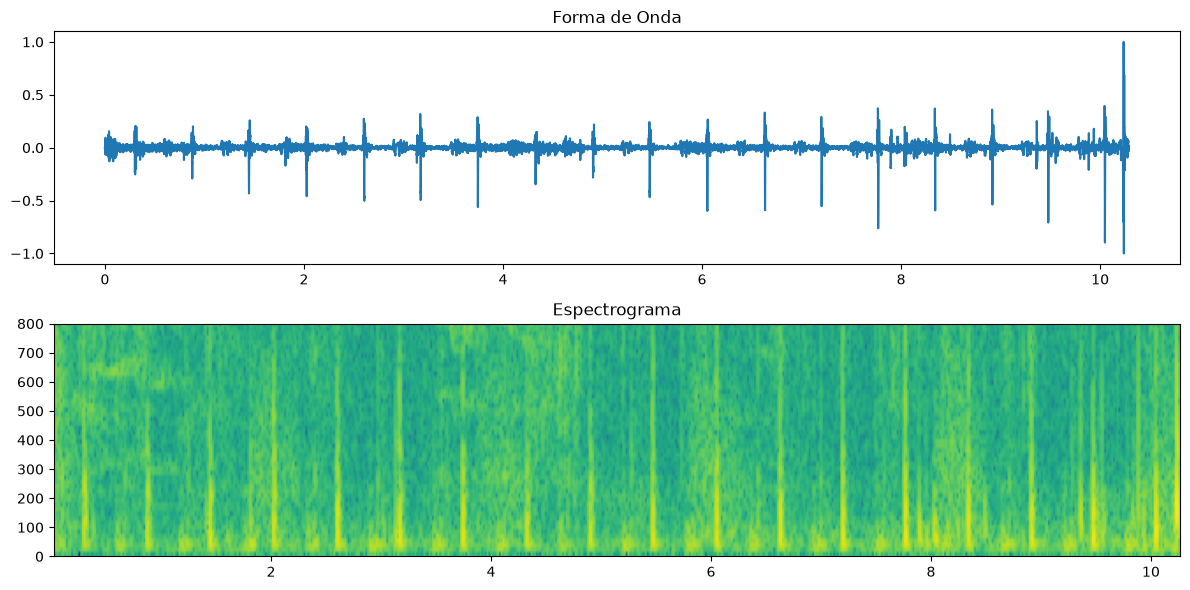

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Audio

t = np.arange(len(x)) / fs
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(t, x); ax[0].set_title("Forma de Onda")
ax[1].specgram(x, Fs=fs, NFFT=256, noverlap=192); ax[1].set_ylim(0, 800)
ax[1].set_title("Espectrograma"); plt.tight_layout(); plt.show()

Audio(x, rate=fs)

In [ ]:
def crop(x, fs, t_start, t_end):
    return x[int(t_start * fs): int(t_end * fs)]

x_5s = crop(x, fs, 2.0, 7.0) #de 2.0 a 7.0 segundos

#janelas de 5 segundos com 50% de sobreposição
def windows(x, fs, win_s=5.0, hop_s=2.5):
    w, h = int(win_s * fs), int(hop_s * fs)
    return np.stack([x[i:i+w] for i in range(0, len(x)-w+1, h)])

W = windows(x, fs)
print(W.shape)    # (n_janelas, amostras_por_janela)